# code_197 · Intervals reflect a model and its uncertainty sources

**Book:** section 37.2. Restart and run all cells. Imports, helpers and generated observations are internal; ordinary execution is offline and CPU-only, with no credentials or files. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_37_GUIDE.md), [execution evidence](../CHAPTER_37_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_197).

Reference runtime: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0 and scikit-learn 1.9.0. Allow two minutes to execute and 45–90 minutes to interpret. Probability and interval contracts identify fitting and calibration roles, uncertainty sources, assessment units and decision costs. Original experiments expose metric behaviour; they are not benchmark reproductions or evidence that the generated law describes inspected structures. Simulator-only truth is labelled separately from observable assessment. No final score chooses a model or threshold. No dependency or asset is added.


In [1]:
import platform,time,json,copy
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn,threadpoolctl
from scipy.special import expit
from IPython.display import display
_THREAD_LIMIT=threadpoolctl.threadpool_limits(1)
START=time.perf_counter();SEED=7897;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__,'threadpoolctl':threadpoolctl.__version__}
print(VERSIONS);print(platform.system(),platform.machine(),'CPU; seed',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':10,'axes.titlesize':9,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0', 'threadpoolctl': '3.7.0'}
Darwin arm64 CPU; seed 7897


<a id="fit-four-uncertainty-models"></a>
 ## Compare actual interval constructions under explicit assumptions
 Source 800 structures have load in [0,1]; 400 familiar and 400 new-load assessment structures have load in [0,1] and [1,1.7]. Deflection is 2+sin(2load)+0.3sensor plus Gaussian noise with scale 0.2+0.4load. Beyond load one, an additional 4(load−1)² term changes the response law. All recipes are fixed and source-fitted. Fit native histogram quantiles 0.05/0.95; 30 source-bootstrap quadratic Ridge regressions whose predictive mixture adds sampled pooled source residuals; conjugate Bayesian quadratic regression with an explicit Normal–inverse-gamma prior; and a heteroscedastic Gaussian likelihood with quadratic mean and log-linear scale. These are different uncertainty models, not equal-budget optimizers. The Bayesian homoscedastic likelihood and the Gaussian mean model are misspecified here, especially under the new regime. Neither prior nor residual resampling guarantees field coverage.


In [2]:
from sklearn.linear_model import Ridge
from sklearn.ensemble import HistGradientBoostingRegressor
from scipy.stats import t as student_t,norm
from scipy.optimize import minimize
def cohort(n,low,high):
    x=np.c_[rng.uniform(low,high,n),rng.normal(size=n)];y=2+np.sin(2*x[:,0])+.3*x[:,1]+4*np.maximum(x[:,0]-1,0)**2+rng.normal(size=n)*(.2+.4*x[:,0]);return x,y
xs,ys=cohort(800,0,1);familiar,yf=cohort(400,0,1);shifted,yh=cohort(400,1,1.7);xa=np.r_[familiar,shifted];ya=np.r_[yf,yh]
def phi(x):return np.c_[np.ones(len(x)),x[:,0],x[:,0]**2,x[:,1]]
A=phi(xs);B=phi(xa);quantiles=[HistGradientBoostingRegressor(loss='quantile',quantile=q,max_iter=120,max_depth=3,early_stopping=False,random_state=SEED).fit(xs,ys) for q in [.05,.95]];rawq=np.column_stack([m.predict(xa) for m in quantiles]);qbounds=np.sort(rawq,axis=1)
ensemble=[Ridge(alpha=.1).fit(A[ids:=rng.integers(0,800,800)],ys[ids]) for _ in range(30)];ep=np.column_stack([m.predict(B) for m in ensemble]);mean_model=Ridge(alpha=.1).fit(A,ys);residual=ys-mean_model.predict(A);residual-=residual.mean();mix=ep[:,rng.integers(0,30,300)]+rng.choice(residual,size=(800,300));ebounds=np.quantile(mix,[.05,.95],axis=1).T;mean_bounds=np.quantile(ep,[.05,.95],axis=1).T
prior_precision=.01*np.eye(4);post_precision=prior_precision+A.T@A;V=np.linalg.inv(post_precision);m=V@A.T@ys;alpha0=2.;beta0=.1;alpha=alpha0+len(ys)/2;beta=beta0+.5*(ys@ys-m@post_precision@m);assert beta>0;posterior_mean=B@m;parameter_scale=np.sqrt(beta/alpha*np.einsum('ij,jk,ik->i',B,V,B));predictive_scale=np.sqrt(beta/alpha*(1+np.einsum('ij,jk,ik->i',B,V,B)));critical=student_t.ppf(.95,2*alpha);bbounds=np.c_[posterior_mean-critical*predictive_scale,posterior_mean+critical*predictive_scale];param_bounds=np.c_[posterior_mean-critical*parameter_scale,posterior_mean+critical*parameter_scale]
def objective(theta):
    mu=A@theta[:4];logs=theta[4]+theta[5]*xs[:,0];z=(ys-mu)*np.exp(-logs);return float(np.mean(logs+.5*z*z+.5*np.log(2*np.pi)))
initial=np.r_[np.linalg.lstsq(A,ys,rcond=None)[0],-.9,.4];fit=minimize(objective,initial,method='L-BFGS-B',bounds=[(-20,20)]*4+[(-5,3),(-5,3)],options={'ftol':1e-12,'gtol':1e-7,'maxiter':1000});assert fit.success;dm=B@fit.x[:4];ds=np.exp(fit.x[4]+fit.x[5]*xa[:,0]);dbounds=np.c_[dm-norm.ppf(.95)*ds,dm+norm.ppf(.95)*ds];bounds={'Quantiles':qbounds,'Bootstrap predictive':ebounds,'Bayesian predictive':bbounds,'Gaussian conditional':dbounds};assert np.all(predictive_scale>parameter_scale);assert all(np.all(b[:,1]>=b[:,0]) for b in bounds.values());RESULTS.update(source_records=800,assessment_familiar=400,assessment_new_load=400,bootstrap_members=30,bootstrap_predictive_draws_per_case=300,Bayesian_prior_precision_diagonal=.01,Bayesian_prior_alpha=alpha0,Bayesian_prior_beta=beta0,Bayesian_posterior_df=2*alpha,distributional_optimizer_success=bool(fit.success),raw_quantile_crossing_fraction=float(np.mean(rawq[:,0]>rawq[:,1])),future_response_law_changes_above_load1=True)


<a id="assess-prediction-versus-parameter-intervals"></a>
 ## Measure coverage and width separately in familiar and new regimes
 Report actual 90% predictive interval coverage and width for each method and regime. Separately assess Bayesian parameter intervals and ensemble mean-spread intervals against observed future outcomes to demonstrate why they are not prediction intervals. That coverage is a category-error diagnostic, not their intended parameter-coverage target. The Bayesian predictive variance includes a future-noise term plus coefficient uncertainty; the parameter interval omits the former. Bootstrap members encode source resampling variation within one restricted family; their agreement cannot detect an absent response mechanism. Visualize twelve fixed final records from each regime, without choosing cases for striking widths. Final outcomes never recalibrate any method.


coverage  mean_width_mm
Quantiles               Familiar    0.8300       1.134984
                        New load    0.7700       1.773139
Bootstrap predictive    Familiar    0.8625       1.300806
                        New load    0.5300       1.386653
Bayesian predictive     Familiar    0.8925       1.306145
                        New load    0.5225       1.389195
Gaussian conditional    Familiar    0.8600       1.228477
                        New load    0.8950       2.708897
Bayesian parameter only Familiar    0.0875       0.087304
                        New load    0.1650       0.439608
Bootstrap mean only     Familiar    0.0625       0.070450
                        New load    0.1800       0.484854

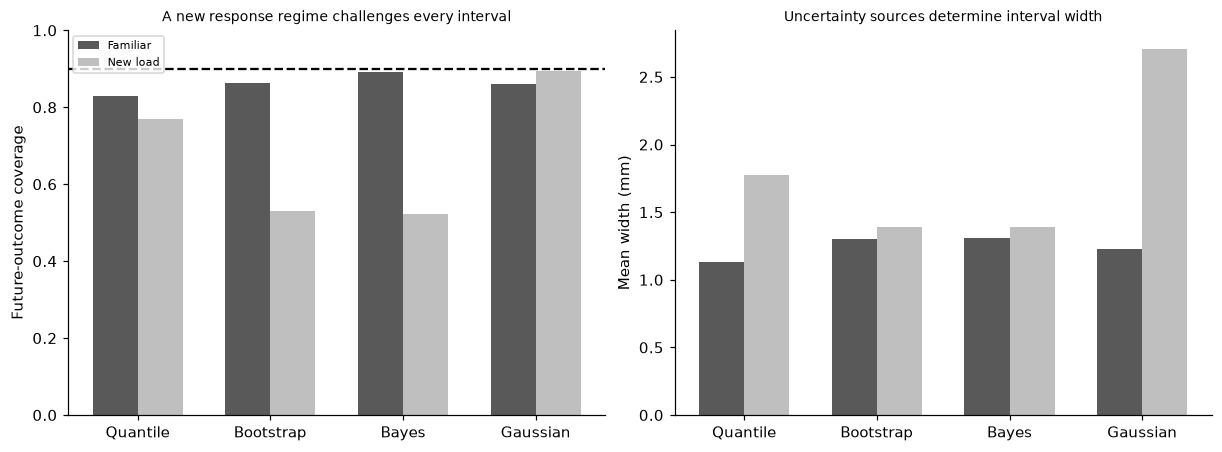

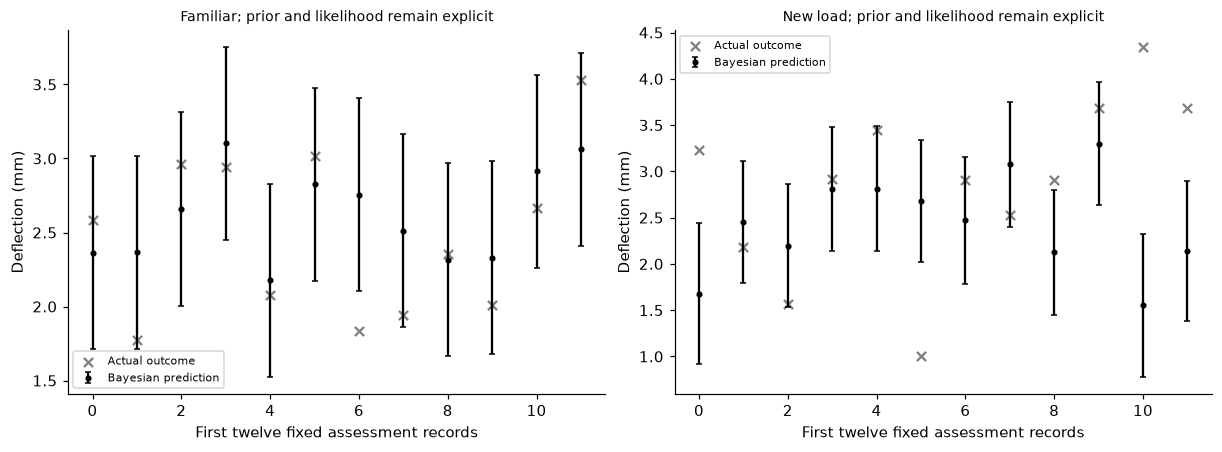

In [3]:
rows={}
for name,b in {**bounds,'Bayesian parameter only':param_bounds,'Bootstrap mean only':mean_bounds}.items():
    rows[name]={}
    for regime,indices in [('Familiar',slice(0,400)),('New load',slice(400,800))]:
        lower,upper=b[indices].T;truth=ya[indices];rows[name][regime]={'coverage':float(np.mean((truth>=lower)&(truth<=upper))),'mean_width_mm':float(np.mean(upper-lower))};assert len(truth)==400
from scipy.stats import invgamma
variance_draws=invgamma.rvs(a=alpha,scale=beta,size=20000,random_state=rng);coefficient_draws=m+rng.multivariate_normal(np.zeros(4),V,size=20000)*np.sqrt(variance_draws)[:,None];future_draws=coefficient_draws@B[0]+rng.normal(size=20000)*np.sqrt(variance_draws);mc_bounds=np.quantile(future_draws,[.05,.95]);mc_error=float(np.max(abs(mc_bounds-bbounds[0])));assert mc_error<.05
assert np.all(param_bounds[:,1]-param_bounds[:,0]<bbounds[:,1]-bbounds[:,0]);RESULTS.update(interval_scores=rows,parameter_interval_outcome_coverage_is_diagnostic_only=True,Bayesian_predictive_independent_MC_quantile_max_error_mm=mc_error,Bayesian_predictive_MC_draws=20000);display(pd.DataFrame({(name,regime):v for name,r in rows.items() for regime,v in r.items()}).T);fig,axes=plt.subplots(1,2,figsize=(11,4));names=list(bounds);xx=np.arange(4)
for j,regime in enumerate(['Familiar','New load']):axes[0].bar(xx+(j-.5)*.34,[rows[k][regime]['coverage'] for k in names],width=.34,color=['.35','.75'][j],label=regime);axes[1].bar(xx+(j-.5)*.34,[rows[k][regime]['mean_width_mm'] for k in names],width=.34,color=['.35','.75'][j],label=regime)
axes[0].axhline(.9,color='black',linestyle='--');axes[0].set(xticks=xx,xticklabels=['Quantile','Bootstrap','Bayes','Gaussian'],ylim=(0,1),ylabel='Future-outcome coverage',title='A new response regime challenges every interval');axes[0].legend(fontsize=7);axes[1].set(xticks=xx,xticklabels=['Quantile','Bootstrap','Bayes','Gaussian'],ylabel='Mean width (mm)',title='Uncertainty sources determine interval width');plt.show();fig,axes=plt.subplots(1,2,figsize=(11,4))
for ax,indices,label in [(axes[0],np.arange(12),'Familiar'),(axes[1],np.arange(400,412),'New load')]:
    b=bbounds[indices];mid=b.mean(1);ax.errorbar(range(12),mid,yerr=np.array([mid-b[:,0],b[:,1]-mid]),fmt='o',color='black',markersize=3,capsize=2,label='Bayesian prediction');ax.scatter(range(12),ya[indices],marker='x',color='.5',label='Actual outcome');ax.set(xlabel='First twelve fixed assessment records',ylabel='Deflection (mm)',title=label+'; prior and likelihood remain explicit');ax.legend(fontsize=7)
plt.show()


In [4]:
summary={'example_id':'code_197','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['actual quantile regression and bootstrap predictive residual mixture', 'conjugate Normal inverse gamma Bayesian parameter and predictive Student t intervals', 'actual heteroscedastic Gaussian likelihood optimization', 'familiar versus shifted-load coverage and width without final recalibration'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["actual quantile regression and bootstrap predictive residual mixture", "conjugate Normal inverse gamma Bayesian parameter and predictive Student t intervals", "actual heteroscedastic Gaussian likelihood optimization", "familiar versus shifted-load coverage and width without final recalibration"], "elapsed_seconds": 0.436, "example_id": "code_197", "hardware": "Darwin arm64 CPU", "results": {"Bayesian_posterior_df": 804.0, "Bayesian_predictive_MC_draws": 20000, "Bayesian_predictive_independent_MC_quantile_max_error_mm": 0.003399377995904951, "Bayesian_prior_alpha": 2.0, "Bayesian_prior_beta": 0.1, "Bayesian_prior_precision_diagonal": 0.01, "assessment_familiar": 400, "assessment_new_load": 400, "bootstrap_members": 30, "bootstrap_predictive_draws_per_case": 300, "distributional_optimizer_success": true, "future_response_law_changes_above_load1": true, "interval_scores": {"Bayesian parameter only": {"Familiar": {"coverage": 0.0875, "mean